In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

In [1]:
%%toc

UsageError: Cell magic `%%toc` not found.


# Dataset
https://dataunodc.un.org/dp-intentional-homicide-victims

In [ ]:
data = pd.read_excel('data_cts_intentional_homicide.xlsx', sheet_name='data_cts_intentional_homicide')
data

,Iso3_code,Country,Region,Subregion,Indicator,Dimension,Category,Sex,Age,Year,Unit of measurement,VALUE,Source
0,ARM,Armenia,Asia,Western Asia,Persons arrested/suspected for intentional hom...,by citizenship,National citizens,Male,Total,2013,Counts,35.000000,CTS
1,CHE,Switzerland,Europe,Western Europe,Persons arrested/suspected for intentional hom...,by citizenship,National citizens,Male,Total,2013,Counts,28.000000,CTS
2,COL,Colombia,Americas,Latin America and the Caribbean,Persons arrested/suspected for intentional hom...,by citizenship,National citizens,Male,Total,2013,Counts,15053.000000,CTS
3,CZE,Czechia,Europe,Eastern Europe,Persons arrested/suspected for intentional hom...,by citizenship,National citizens,Male,Total,2013,Counts,69.000000,CTS
4,DEU,Germany,Europe,Western Europe,Persons arrested/suspected for intentional hom...,by citizenship,National citizens,Male,Total,2013,Counts,455.000000,CTS
...,...,...,...,...,...,...,...,...,...,...,...,...,...
121791,MNG,Mongolia,Asia,Eastern Asia,Death due to intentional homicide in prison,Total,Total,Total,Total,2023,"Rate per 100,000 population",0.000000,CTS/SDG
121792,PRI,Puerto Rico,Americas,Latin America and the Caribbean,Death due to intentional homicide in prison,Total,Total,Total,Total,2023,"Rate per 100,000 population",0.061690,SDG/CTS
121793,ROU,Romania,Europe,Eastern Europe,Death due to intentional homicide in prison,Total,Total,Total,Total,2023,"Rate per 100,000 population",0.010461,CTS/SDG
121794,RUS,Russian Federation,Europe,Eastern Europe,Death due to intentional homicide in prison,Total,Total,Total,Total,2023,"Rate per 100,000 population",0.004125,SDG/CTS


In [ ]:
# Filter the DataFrame to keep only rows where 'Unit of measurement' is 'Counts'
data_counts = data[data['Unit of measurement'] == 'Counts']

# Display the first few rows of the filtered DataFrame
display(data_counts.head())

# Display information about the filtered DataFrame to see the number of rows
print("\nInformation about the filtered DataFrame:")
data_counts.info()

,Iso3_code,Country,Region,Subregion,Indicator,Dimension,Category,Sex,Age,Year,Unit of measurement,VALUE,Source
0,ARM,Armenia,Asia,Western Asia,Persons arrested/suspected for intentional hom...,by citizenship,National citizens,Male,Total,2013,Counts,35.0,CTS
1,CHE,Switzerland,Europe,Western Europe,Persons arrested/suspected for intentional hom...,by citizenship,National citizens,Male,Total,2013,Counts,28.0,CTS
2,COL,Colombia,Americas,Latin America and the Caribbean,Persons arrested/suspected for intentional hom...,by citizenship,National citizens,Male,Total,2013,Counts,15053.0,CTS
3,CZE,Czechia,Europe,Eastern Europe,Persons arrested/suspected for intentional hom...,by citizenship,National citizens,Male,Total,2013,Counts,69.0,CTS
4,DEU,Germany,Europe,Western Europe,Persons arrested/suspected for intentional hom...,by citizenship,National citizens,Male,Total,2013,Counts,455.0,CTS



Information about the filtered DataFrame:
<class 'pandas.core.frame.DataFrame'>
Index: 63397 entries, 0 to 63396
Data columns (total 13 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Iso3_code            63397 non-null  object 
 1   Country              63397 non-null  object 
 2   Region               63397 non-null  object 
 3   Subregion            63397 non-null  object 
 4   Indicator            63397 non-null  object 
 5   Dimension            63397 non-null  object 
 6   Category             63397 non-null  object 
 7   Sex                  63397 non-null  object 
 8   Age                  63397 non-null  object 
 9   Year                 63397 non-null  int64  
 10  Unit of measurement  63397 non-null  object 
 11  VALUE                63397 non-null  float64
 12  Source               63397 non-null  object 
dtypes: float64(1), int64(1), object(11)
memory usage: 6.8+ MB


# Aantallen per regio

In [ ]:
# Group the data by 'Region' and 'Year' and sum the 'VALUE' column
homicide_counts_per_region_year = data_counts.groupby(['Region', 'Year'])['VALUE'].sum().reset_index()

# Rename the 'VALUE' column to something more descriptive like 'Total_Counts'
homicide_counts_per_region_year = homicide_counts_per_region_year.rename(columns={'VALUE': 'Total_Counts'})

# Display the resulting table
display(homicide_counts_per_region_year)

,Region,Year,Total_Counts
0,Africa,1990,2812.0
1,Africa,1991,1880.0
2,Africa,1992,2064.0
3,Africa,1993,2026.0
4,Africa,1994,28258.0
...,...,...,...
170,Oceania,2020,1954.0
171,Oceania,2021,1764.0
172,Oceania,2022,2045.0
173,Oceania,2023,1137.0


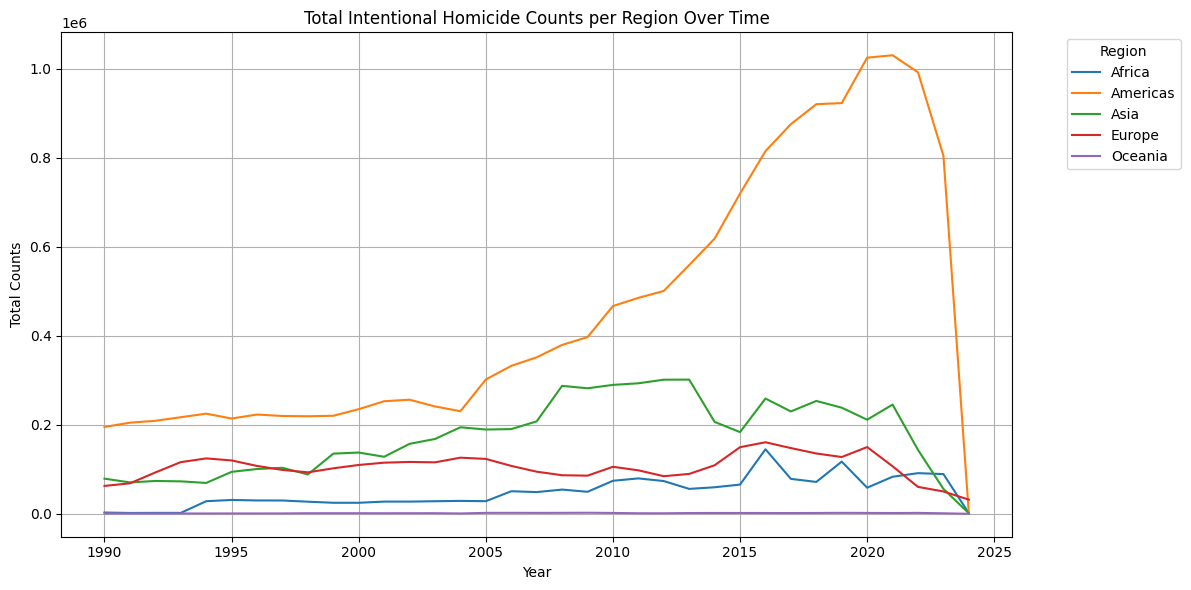

In [ ]:
# Create a line plot of total counts per region over the years
plt.figure(figsize=(12, 6))
sns.lineplot(data=homicide_counts_per_region_year, x='Year', y='Total_Counts', hue='Region')

plt.title('Total Intentional Homicide Counts per Region Over Time')
plt.xlabel('Year')
plt.ylabel('Total Counts')
plt.grid(True)
plt.legend(title='Region', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

# Aantallen per subregio

,Subregion,Year,Total_Counts
0,Australia and New Zealand,1990,811.348066
1,Australia and New Zealand,1991,733.602210
2,Australia and New Zealand,1992,668.596685
3,Australia and New Zealand,1993,707.419890
4,Australia and New Zealand,1994,696.850829
...,...,...,...
558,Western Europe,2020,18765.000000
559,Western Europe,2021,18491.000000
560,Western Europe,2022,19477.000000
561,Western Europe,2023,16451.000000


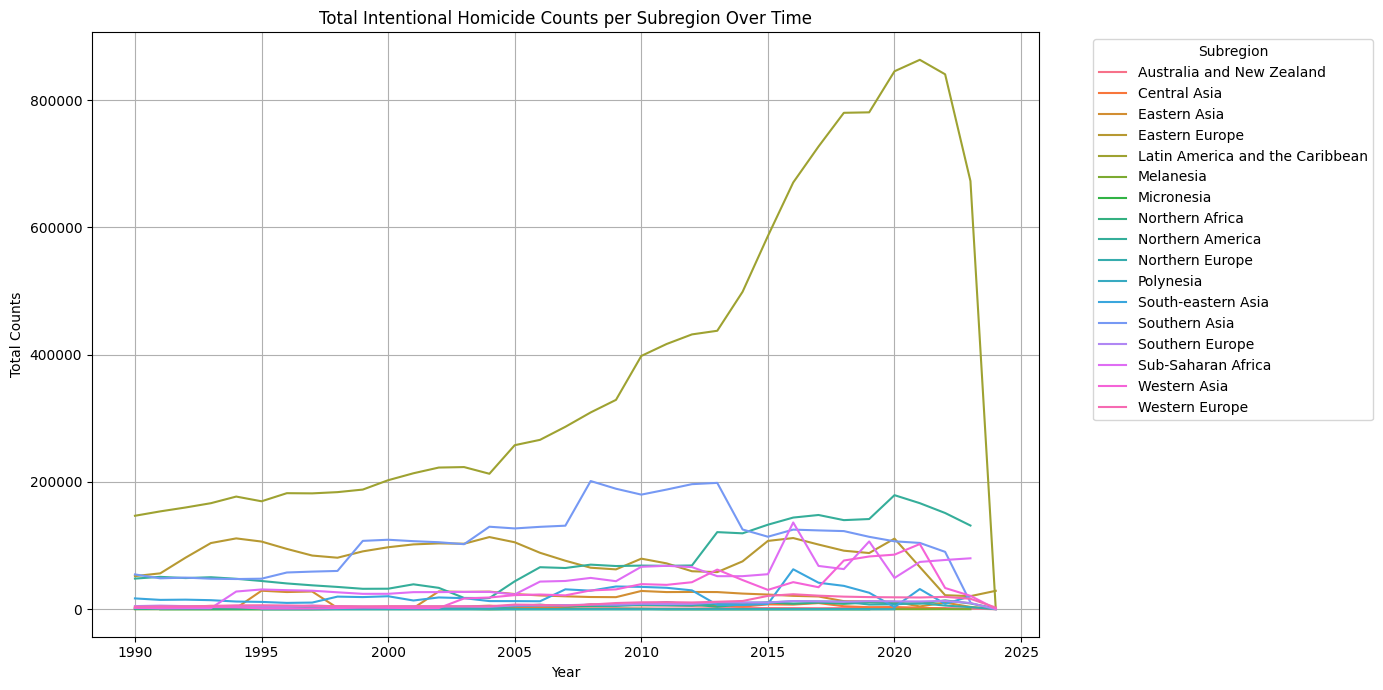

In [ ]:
# Group the data by 'Subregion' and 'Year' and sum the 'VALUE' column
homicide_counts_per_subregion_year = data_counts.groupby(['Subregion', 'Year'])['VALUE'].sum().reset_index()

# Rename the 'VALUE' column to something more descriptive like 'Total_Counts'
homicide_counts_per_subregion_year = homicide_counts_per_subregion_year.rename(columns={'VALUE': 'Total_Counts'})

# Display the resulting table
display(homicide_counts_per_subregion_year)

# Create a line plot of total counts per subregion over the years
plt.figure(figsize=(14, 7))
sns.lineplot(data=homicide_counts_per_subregion_year, x='Year', y='Total_Counts', hue='Subregion')

plt.title('Total Intentional Homicide Counts per Subregion Over Time')
plt.xlabel('Year')
plt.ylabel('Total Counts')
plt.grid(True)
plt.legend(title='Subregion', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

# Aantallen per geslacht

In [ ]:
# Group the data by 'Sex' and 'Year' and sum the 'VALUE' column
homicide_counts_by_sex_year = data_counts.groupby(['Sex', 'Year'])['VALUE'].sum().reset_index()

# Rename the 'VALUE' column to something more descriptive
homicide_counts_by_sex_year = homicide_counts_by_sex_year.rename(columns={'VALUE': 'Total_Counts'})

# Display the resulting table (first few rows)
display(homicide_counts_by_sex_year.head())

,Sex,Year,Total_Counts
0,Female,1990,19476.109658
1,Female,1991,20464.758820
2,Female,1992,22976.396499
3,Female,1993,26676.327911
4,Female,1994,27220.196990


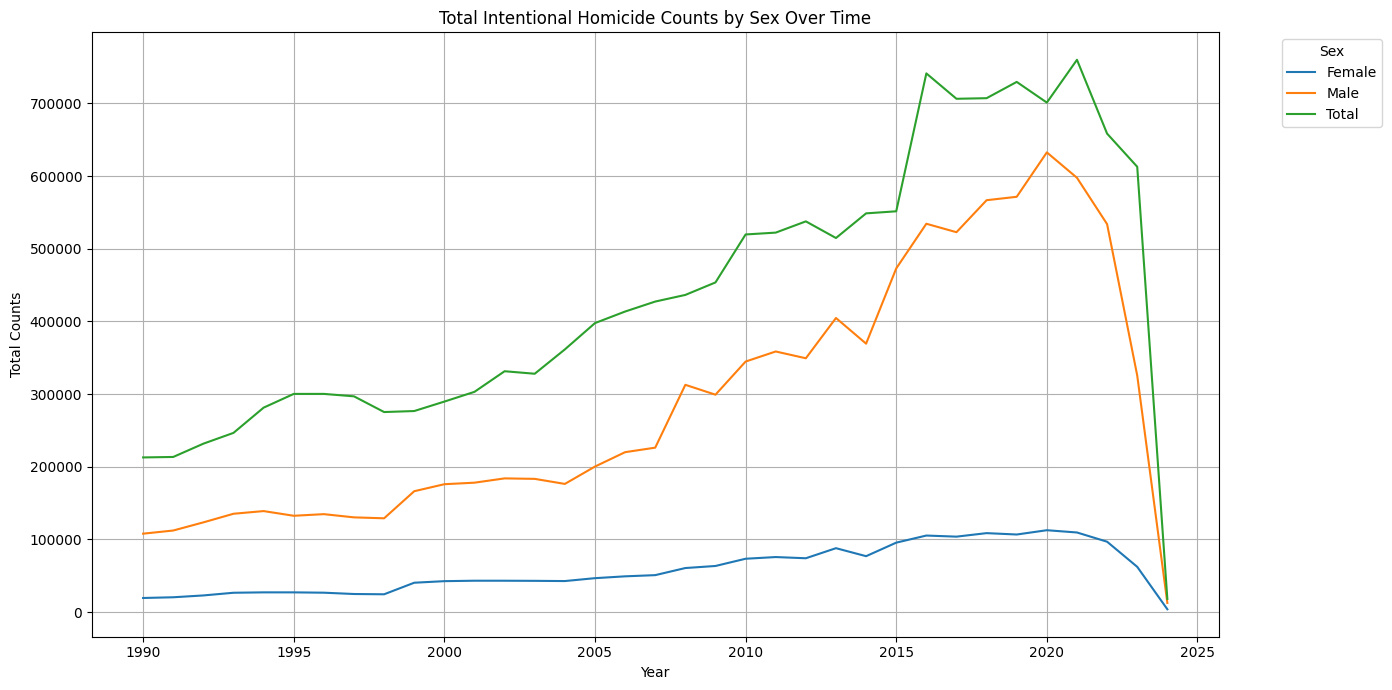

In [ ]:
# Create a line plot of total counts by Sex over the years
plt.figure(figsize=(14, 7))
sns.lineplot(data=homicide_counts_by_sex_year, x='Year', y='Total_Counts', hue='Sex')

plt.title('Total Intentional Homicide Counts by Sex Over Time')
plt.xlabel('Year')
plt.ylabel('Total Counts')
plt.grid(True)
plt.legend(title='Sex', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

# Aantallen per leeftijd

In [ ]:
# Group the data by 'Age', and 'Year' and sum the 'VALUE' column
homicide_counts_by_age_year = data_counts.groupby(['Age', 'Year'])['VALUE'].sum().reset_index()

# Filter out rows where 'Age' is 'Total'
homicide_counts_by_age_year_filtered = homicide_counts_by_age_year[homicide_counts_by_age_year['Age'] != 'Total']

# Rename the 'VALUE' column to something more descriptive
homicide_counts_by_age_year_filtered = homicide_counts_by_age_year_filtered.rename(columns={'VALUE': 'Total_Counts'})

# Display the resulting table (first few rows)
display(homicide_counts_by_age_year_filtered.head())

,Age,Year,Total_Counts
0,0-9,2010,117.000000
1,0-9,2011,140.454545
2,0-9,2012,159.008264
3,0-9,2013,328.969072
4,0-9,2014,370.844037


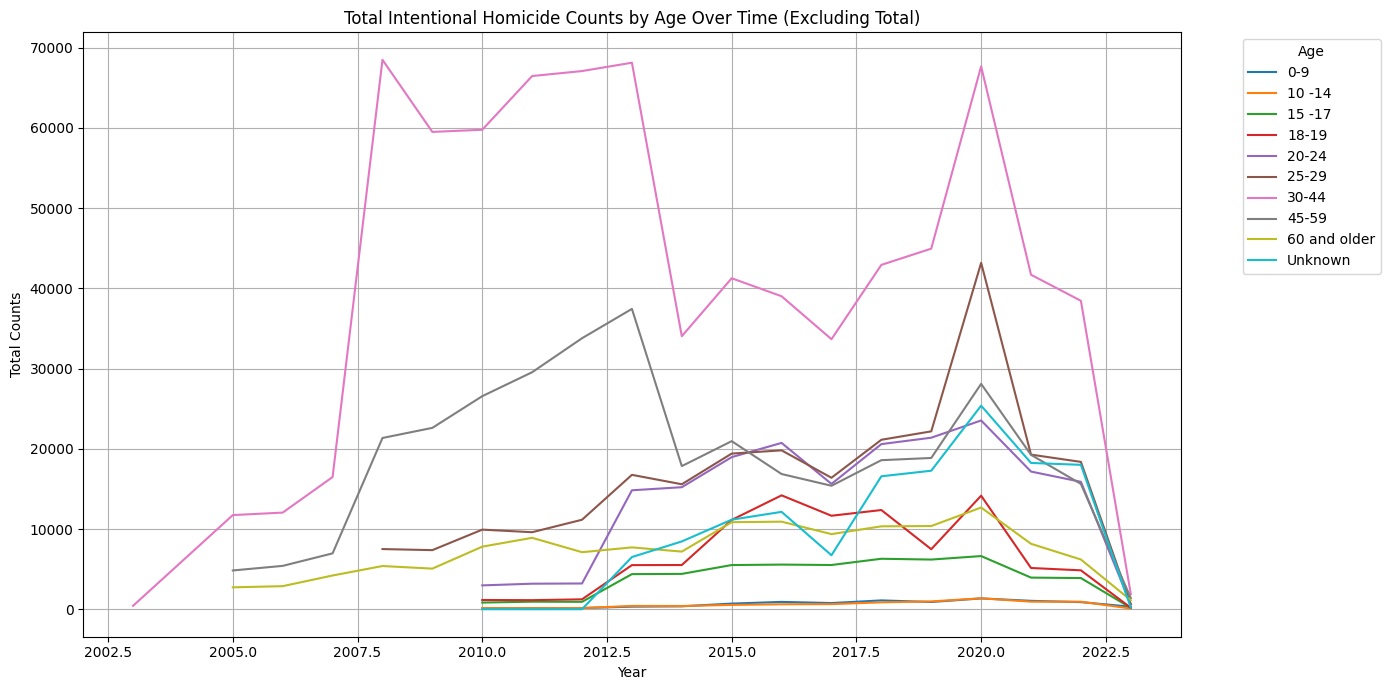

In [ ]:
# Create a line plot of total counts by Age over the years, excluding 'Total'
plt.figure(figsize=(14, 7))
sns.lineplot(data=homicide_counts_by_age_year_filtered, x='Year', y='Total_Counts', hue='Age')

plt.title('Total Intentional Homicide Counts by Age Over Time (Excluding Total)')
plt.xlabel('Year')
plt.ylabel('Total Counts')
plt.grid(True)
plt.legend(title='Age', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

# Aantallen per oorzaak homicide

In [ ]:
# Group the data by 'Indicator' and 'Year' and sum the 'VALUE' column
homicide_counts_by_indicator_year = data_counts.groupby(['Indicator', 'Year'])['VALUE'].sum().reset_index()

# Rename the 'VALUE' column to something more descriptive
homicide_counts_by_indicator_year = homicide_counts_by_indicator_year.rename(columns={'VALUE': 'Total_Counts'})

# Display the resulting table (first few rows)
display(homicide_counts_by_indicator_year.head())

,Indicator,Year,Total_Counts
0,Death due to intentional homicide in prison,2010,191.0
1,Death due to intentional homicide in prison,2011,219.0
2,Death due to intentional homicide in prison,2012,267.0
3,Death due to intentional homicide in prison,2013,313.0
4,Death due to intentional homicide in prison,2014,497.0


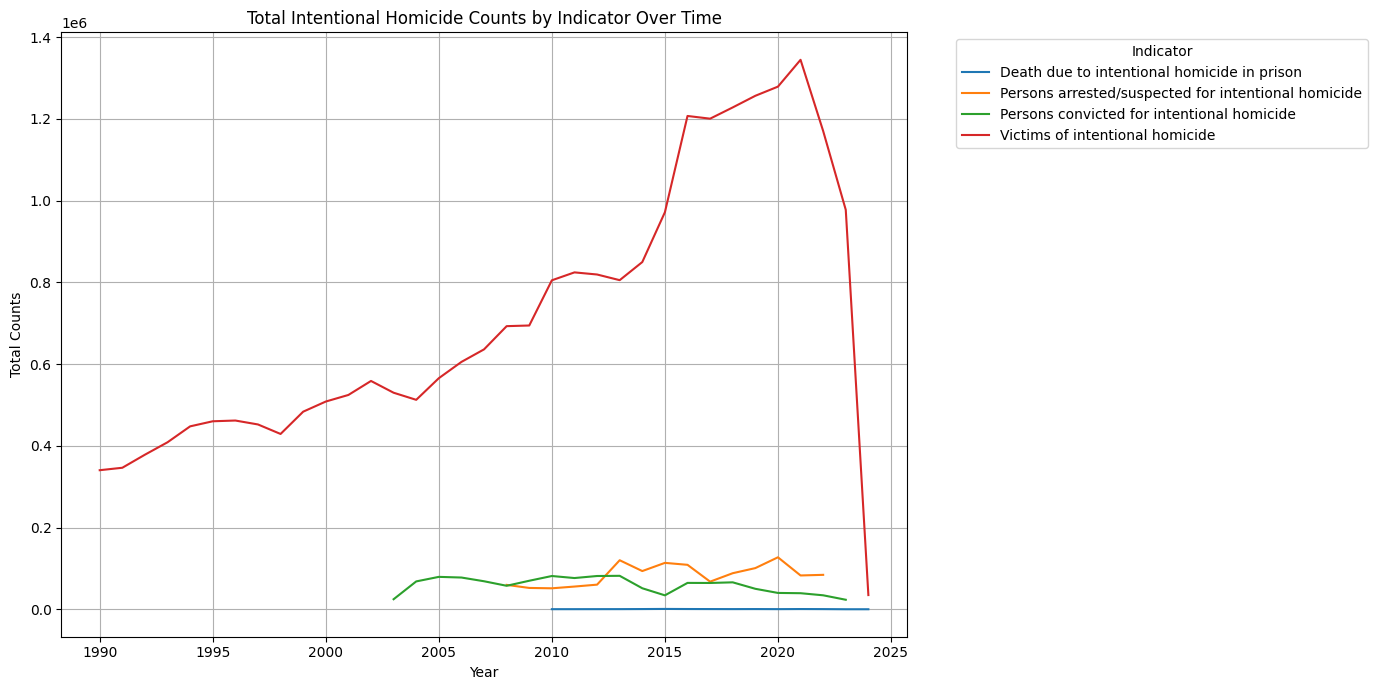

In [ ]:
# Create a line plot of total counts by Indicator over the years
plt.figure(figsize=(14, 7))
sns.lineplot(data=homicide_counts_by_indicator_year, x='Year', y='Total_Counts', hue='Indicator')

plt.title('Total Intentional Homicide Counts by Indicator Over Time')
plt.xlabel('Year')
plt.ylabel('Total Counts')
plt.grid(True)
plt.legend(title='Indicator', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

# Regressie-analyse: leeftijd als voorspeller

In [ ]:
from sklearn.preprocessing import OrdinalEncoder
import numpy as np

# Define the order of age categories based on unique values found in the data
# Including 'Total' and 'Unknown' at the end as they don't fit neatly into ranges
age_order = ['0-9', '10 -14', '15 -17', '10-17', '18-19', '20-24', '18-24', '25-29', '25-39', '30-44', '40-59', '45-59', '60+', '60 and older', 'Total', 'Unknown']

# Create an OrdinalEncoder instance with the specified order
encoder = OrdinalEncoder(categories=[age_order], handle_unknown='error') # Changed handle_unknown to 'error'

# Apply ordinal encoding to the 'Age' column
# Reshape the column to be a 2D array as required by the encoder
data_counts['Age_Encoded'] = encoder.fit_transform(data_counts[['Age']])

# Display the first few rows with the new 'Age_Encoded' column
display(data_counts.head())

# Display the data types to confirm the new column is numerical
print("\nData types after encoding:")
data_counts.info()

/tmp/ipython-input-604257209.py:13: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data_counts['Age_Encoded'] = encoder.fit_transform(data_counts[['Age']])


,Iso3_code,Country,Region,Subregion,Indicator,Dimension,Category,Sex,Age,Year,Unit of measurement,VALUE,Source,Age_Encoded
0,ARM,Armenia,Asia,Western Asia,Persons arrested/suspected for intentional hom...,by citizenship,National citizens,Male,Total,2013,Counts,35.0,CTS,14.0
1,CHE,Switzerland,Europe,Western Europe,Persons arrested/suspected for intentional hom...,by citizenship,National citizens,Male,Total,2013,Counts,28.0,CTS,14.0
2,COL,Colombia,Americas,Latin America and the Caribbean,Persons arrested/suspected for intentional hom...,by citizenship,National citizens,Male,Total,2013,Counts,15053.0,CTS,14.0
3,CZE,Czechia,Europe,Eastern Europe,Persons arrested/suspected for intentional hom...,by citizenship,National citizens,Male,Total,2013,Counts,69.0,CTS,14.0
4,DEU,Germany,Europe,Western Europe,Persons arrested/suspected for intentional hom...,by citizenship,National citizens,Male,Total,2013,Counts,455.0,CTS,14.0



Data types after encoding:
<class 'pandas.core.frame.DataFrame'>
Index: 63397 entries, 0 to 63396
Data columns (total 14 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Iso3_code            63397 non-null  object 
 1   Country              63397 non-null  object 
 2   Region               63397 non-null  object 
 3   Subregion            63397 non-null  object 
 4   Indicator            63397 non-null  object 
 5   Dimension            63397 non-null  object 
 6   Category             63397 non-null  object 
 7   Sex                  63397 non-null  object 
 8   Age                  63397 non-null  object 
 9   Year                 63397 non-null  int64  
 10  Unit of measurement  63397 non-null  object 
 11  VALUE                63397 non-null  float64
 12  Source               63397 non-null  object 
 13  Age_Encoded          63397 non-null  float64
dtypes: float64(2), int64(1), object(11)
memory usage: 7.3+ MB


In [ ]:
import statsmodels.api as sm

# Define the independent variable (x) and dependent variable (y)
X = data_counts['Age_Encoded']
y = data_counts['VALUE']

# Add a constant to the independent variable for the intercept
X = sm.add_constant(X)

# Create a linear regression model
model = sm.OLS(y, X)

# Fit the model to the data
results = model.fit()

# Print the summary of the regression results
print(results.summary())

                            OLS Regression Results                            
Dep. Variable:                  VALUE   R-squared:                       0.006
Model:                            OLS   Adj. R-squared:                  0.006
Method:                 Least Squares   F-statistic:                     367.4
Date:                Thu, 30 Oct 2025   Prob (F-statistic):           1.19e-81
Time:                        19:02:48   Log-Likelihood:            -5.9150e+05
No. Observations:               63397   AIC:                         1.183e+06
Df Residuals:                   63395   BIC:                         1.183e+06
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                  coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------
const        -133.3663     31.369     -4.252      

Interpret the OLS regression results<br>
Certainly! Here's an interpretation of the OLS regression results:
<p>
**R-squared:** This value (0.006) indicates that only a very small percentage (0.6%) of the variance in intentional homicide counts can be explained by the encoded age. This suggests that encoded age, by itself, is not a strong predictor of homicide counts based on this linear model.<p>
**Adj. R-squared:** This is a modified version of R-squared that is adjusted for the number of predictors in the model. It's also 0.006, reinforcing that the model has very little explanatory power.<p>
**F-statistic and Prob (F-statistic):** The F-statistic (367.4) and its associated p-value (1.19e-81, which is very close to 0) indicate that the overall regression model is statistically significant. <p>This means that the relationship between encoded age and homicide counts is unlikely to be due to random chance. However, while statistically significant, the effect size (as indicated by R-squared) is very small.<p>
**Coefficients (coef):**
const (-133.3663): This is the estimated intercept of the regression line. It represents the predicted homicide count when the encoded age is 0. However, in the context of encoded age categories, interpreting the intercept directly might not be very meaningful, especially if 0 doesn't represent a realistic or relevant age group.<p>
**Age_Encoded (48.7999):** This is the estimated coefficient for the 'Age_Encoded' variable. It suggests that for every one-unit increase in the encoded age (moving from one age category to the next in our defined order), the predicted intentional homicide count increases by approximately 48.8.
std err: This is the standard error of the coefficients, measuring the variability of the coefficient estimates.<p>
**t and P>|t|:** The t-statistic and its p-value for each coefficient test the significance of each predictor. The p-value for 'Age_Encoded' (0.000) is less than the typical significance level (0.05), indicating that the encoded age is a statistically significant predictor of homicide counts in this model.<p>
**[0.025 0.975]:** These are the 95% confidence intervals for the coefficients. We can be 95% confident that the true coefficient for 'Age_Encoded' lies between 43.810 and 53.790.<p>
**Omnibus, Prob(Omnibus), Jarque-Bera (JB), Prob(JB), Skew, Kurtosis:** These are tests for the normality of the residuals. The results (Prob(Omnibus) = 0.000, Prob(JB) = 0.00) suggest that the residuals are not normally distributed. This violates one of the assumptions of linear regression and indicates that the model might not be the best fit for the data. The high Skew (11.958) and Kurtosis (176.955) also point to a non-normal and heavy-tailed distribution of residuals, likely due to the skewed nature of the 'VALUE' (homicide counts) data.<p>
**Durbin-Watson:** This statistic (1.995) tests for the presence of autocorrelation in the residuals. A value close to 2 suggests no significant autocorrelation.<p>
**Cond. No.:** This measures multicollinearity (correlation between independent variables). A high value can indicate multicollinearity issues, but with only one independent variable, this is not a concern here.<p>
In summary, while the encoded age is a statistically significant predictor, the linear model explains very little of the variation in homicide counts. The non-normal residuals suggest that a simple linear regression might not be the most appropriate model for this data. The relationship between age categories and homicide counts might be more complex and not strictly linear.

# Regressie-analyse: regio als voorspeller

In [ ]:
import statsmodels.api as sm
import pandas as pd

# Create dummy variables for the 'Region' column and convert them to integers
X_region = pd.get_dummies(data_counts['Region'], drop_first=True).astype(int)

# Define the dependent variable (y)
y = data_counts['VALUE']

# Add a constant to the independent variable for the intercept
X_region = sm.add_constant(X_region)

# Create a linear regression model
model_region = sm.OLS(y, X_region)

# Fit the model to the data
results_region = model_region.fit()

# Print the summary of the regression results
print(results_region.summary())

                            OLS Regression Results                            
Dep. Variable:                  VALUE   R-squared:                       0.010
Model:                            OLS   Adj. R-squared:                  0.010
Method:                 Least Squares   F-statistic:                     166.0
Date:                Thu, 30 Oct 2025   Prob (F-statistic):          1.14e-141
Time:                        19:20:01   Log-Likelihood:            -5.9136e+05
No. Observations:               63397   AIC:                         1.183e+06
Df Residuals:                   63392   BIC:                         1.183e+06
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const        675.7244     54.375     12.427      0.0

Here's an interpretation of the OLS regression results using 'Region' as a predictor:

R-squared: This value (0.010) indicates that a very small percentage (1.0%) of the variance in intentional homicide counts can be explained by the region. This suggests that region, by itself, is not a strong predictor of homicide counts based on this linear model, although it explains slightly more variance than encoded age did (0.6%).<p>
Adj. R-squared: Similar to R-squared, this value (0.010) reinforces that the model has very little explanatory power.<p>
F-statistic and Prob (F-statistic): The F-statistic (166.0) and its associated p-value (1.14e-141, very close to 0) indicate that the overall regression model is statistically significant. This means that the relationship between region and homicide counts is unlikely to be due to random chance. While statistically significant, the effect size is quite small.<p>
Coefficients (coef):
const (675.7244): This is the estimated intercept. In the context of dummy variables with drop_first=True, the intercept represents the mean homicide count for the region that was dropped (the reference category). Looking at the dummy variable columns ('Americas', 'Asia', 'Europe', 'Oceania'), the dropped category is 'Africa'. So, the average homicide count for Africa is estimated to be around 675.72.<p>
Americas (-7.4334): This is the estimated difference in mean homicide counts between the Americas and the reference category (Africa). The coefficient is negative and not statistically significant (P>|t| = 0.897 > 0.05), suggesting there is no significant difference in average homicide counts between the Americas and Africa in this model.<br>
Asia (61.7648): This coefficient represents the estimated difference in mean homicide counts between Asia and Africa. It is positive but not statistically significant (P>|t| = 0.320 > 0.05), suggesting no significant difference in average homicide counts between Asia and Africa.<br>
Europe (-542.6359): This coefficient represents the estimated difference in mean homicide counts between Europe and Africa. It is negative and statistically significant (P>|t| = 0.000 < 0.05). This suggests that, on average, the homicide counts in Europe are significantly lower than in Africa, by approximately 542.64.<br>
Oceania (-639.3137): This coefficient represents the estimated difference in mean homicide counts between Oceania and Africa. It is negative and statistically significant (P>|t| = 0.000 < 0.05). This suggests that, on average, the homicide counts in Oceania are significantly lower than in Africa, by approximately 639.31.<p>
std err, t, and P>|t|: These columns are interpreted the same way as before, indicating the standard error, t-statistic, and p-value for each coefficient, testing their statistical significance.<p>
[0.025 0.975]: These are the 95% confidence intervals for the coefficients.<p>
Omnibus, Prob(Omnibus), Jarque-Bera (JB), Prob(JB), Skew, Kurtosis: Similar to the previous regression, these tests indicate that the residuals are not normally distributed, suggesting that a simple linear regression might not be the best model for this data due to the likely skewed nature of the homicide counts.<p>
Durbin-Watson: This statistic (1.983) suggests no significant autocorrelation in the residuals.<p>
Cond. No.: This value (13.9) is low, indicating no significant multicollinearity issues among the predictor variables (the dummy variables).<p>
In summary, the region is a statistically significant predictor of homicide counts, and specifically, Europe and Oceania have significantly lower estimated average homicide counts compared to Africa (the reference category) based on this model. However, similar to the age regression, the model explains only a small portion of the variance in homicide counts, and the residuals are not normally distributed.

# Regressie-analyse: subregio als voorspeller

In [ ]:
import statsmodels.api as sm
import pandas as pd

# Create dummy variables for the 'Subregion' column and convert them to integers
X_subregion = pd.get_dummies(data_counts['Subregion'], drop_first=True).astype(int)

# Define the dependent variable (y)
y = data_counts['VALUE']

# Add a constant to the independent variable for the intercept
X_subregion = sm.add_constant(X_subregion)

# Create a linear regression model
model_subregion = sm.OLS(y, X_subregion)

# Fit the model to the data
results_subregion = model_subregion.fit()

# Print the summary of the regression results
print(results_subregion.summary())

                            OLS Regression Results                            
Dep. Variable:                  VALUE   R-squared:                       0.032
Model:                            OLS   Adj. R-squared:                  0.031
Method:                 Least Squares   F-statistic:                     129.1
Date:                Thu, 30 Oct 2025   Prob (F-statistic):               0.00
Time:                        19:17:00   Log-Likelihood:            -5.9067e+05
No. Observations:               63397   AIC:                         1.181e+06
Df Residuals:                   63380   BIC:                         1.182e+06
Df Model:                          16                                         
Covariance Type:            nonrobust                                         
                                      coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------------------------
const     

Here's an interpretation of the OLS regression results using 'Subregion' as a predictor:

R-squared: This value (0.032) indicates that a small percentage (3.2%) of the variance in intentional homicide counts can be explained by the subregion. This is a higher R-squared value compared to using just 'Region' (1.0%) or encoded 'Age' (0.6%), suggesting that subregion is a better predictor among these single variables, although it still explains a limited amount of the variance.<p>
Adj. R-squared: This value (0.031) is close to the R-squared, reinforcing that the model's explanatory power is limited but slightly better than the previous models.<p>
F-statistic and Prob (F-statistic): The F-statistic (129.1) and its associated p-value (0.00) indicate that the overall regression model is statistically significant. This means that the relationship between subregion and homicide counts is unlikely to be due to random chance.<p>
Coefficients (coef): The interpretation of the coefficients for the dummy variables is similar to the 'Region' analysis. The const (37.1802) represents the mean homicide count for the reference category (the subregion that was dropped when creating dummy variables). To identify the reference category, you would need to look at the columns created for the dummy variables (X_subregion in this case) **and see which subregion is missing (Australia and New Zealand)**. Each subsequent coefficient represents the estimated difference in mean homicide counts between that specific subregion and the reference category, holding other factors constant.<br>
Look at the P>|t| column for each subregion coefficient. If the p-value is less than your chosen significance level (commonly 0.05), the estimated difference in mean homicide counts between that subregion and the reference category is statistically significant.<p>
For example, 'Southern Asia' has a large positive and highly significant coefficient (2962.5153 with P>|t| = 0.000), suggesting that, on average, homicide counts in Southern Asia are significantly higher than in the reference subregion.
Conversely, some subregions like 'Northern Europe' (-13.5281 with P>|t| = 0.875) do not show a statistically significant difference in mean homicide counts compared to the reference subregion.<p>
std err, t, and P>|t|: These columns provide the standard error, t-statistic, and p-value for each coefficient, helping assess their statistical significance.<p>
[0.025 0.975]: These are the 95% confidence intervals for the coefficients.<p>
Omnibus, Prob(Omnibus), Jarque-Bera (JB), Prob(JB), Skew, Kurtosis: Similar to the previous regressions, these tests indicate that the residuals are not normally distributed, likely due to the skewed nature of the homicide counts. This suggests that a simple linear regression might not fully capture the complexity of the data.<p>
Durbin-Watson: This statistic (1.990) suggests no significant autocorrelation in the residuals.<p>
Cond. No.: This value (44.3) is higher than in the 'Region' regression, but still relatively low, indicating no severe multicollinearity issues among the subregion dummy variables.<p>
In summary, subregion is a statistically significant predictor of homicide counts and explains a larger portion of the variance compared to region or encoded age. Several subregions show statistically significant differences in estimated average homicide counts compared to the reference subregion. However, the model still explains a relatively small amount of the total variance, and the non-normal residuals suggest that a more complex model might be needed for a better fit.

# Naive Bayes Classification
We gaan het land voorspellen op basis van de regio en de subregio.

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import MultinomialNB
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import accuracy_score, classification_report
import numpy as np

# Select features (Region, Subregion) and target (Country)
features = ['Region', 'Subregion']
target = 'Country'

X = data_counts[features]
y = data_counts[target]

# Encode categorical features and target variable
# Use LabelEncoder for the target variable 'Country'
label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(y)

# Use one-hot encoding for features 'Region' and 'Subregion'
X_encoded = pd.get_dummies(X, columns=features)

# Split data into training and testing sets
X_train, X_test, y_train_encoded, y_test_encoded = train_test_split(
    X_encoded, y_encoded, test_size=0.3, random_state=42
)

# Initialize and train a Multinomial Naive Bayes classifier
# MultinomialNB is suitable for count data, which is appropriate here after one-hot encoding
naive_bayes_model = MultinomialNB()
naive_bayes_model.fit(X_train, y_train_encoded)

# Make predictions on the test set
y_pred_encoded = naive_bayes_model.predict(X_test)

# Evaluate the model
accuracy = accuracy_score(y_test_encoded, y_pred_encoded)
print(f"Accuracy: {accuracy}")

# Display classification report
# To get the original country names in the report, we need to match labels in y_test_encoded
# with the target names from the label encoder.
unique_test_labels = np.unique(y_test_encoded)
target_names_subset = label_encoder.inverse_transform(unique_test_labels)

print("\nClassification Report:")
print(classification_report(
    y_test_encoded, y_pred_encoded, labels=unique_test_labels, target_names=target_names_subset, zero_division='warn'
))

Accuracy: 0.16072555205047317

Classification Report:
                                                precision    recall  f1-score   support

                                   Afghanistan       0.00      0.00      0.00         7
                                       Albania       0.00      0.00      0.00       133
                                       Algeria       0.00      0.00      0.00       154
                                American Samoa       0.00      0.00      0.00        10
                                       Andorra       0.00      0.00      0.00        93
                                        Angola       0.00      0.00      0.00         3
                                      Anguilla       0.00      0.00      0.00        13
                           Antigua and Barbuda       0.00      0.00      0.00       185
                                     Argentina       0.00      0.00      0.00       157
                                       Armenia       0.15      1.

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [ ]:
from sklearn.metrics import classification_report
import pandas as pd

# Calculate the classification report as a dictionary
classification_report_dict = classification_report(
    y_test_encoded, y_pred_encoded, labels=unique_test_labels, target_names=target_names_subset, output_dict=True, zero_division='warn'
)

# Convert the dictionary to a pandas DataFrame
classification_report_df = pd.DataFrame(classification_report_dict).T

# Remove the 'accuracy', 'macro avg', and 'weighted avg' rows as they are not per-country metrics
classification_report_df = classification_report_df.drop(['accuracy', 'macro avg', 'weighted avg'], errors='ignore')

# Sort the DataFrame by F1-score in descending order to see the best predicted countries
classification_report_sorted_f1 = classification_report_df.sort_values(by='f1-score', ascending=False)

# Display the top 10 countries with the highest F1-score
print("Top 10 countries predicted best by F1-score:")
display(classification_report_sorted_f1.head(10))

# Sort the DataFrame by Precision in descending order to see the countries with highest precision
classification_report_sorted_precision = classification_report_df.sort_values(by='precision', ascending=False)

# Display the top 10 countries with the highest Precision
print("\nTop 10 countries predicted best by Precision:")
display(classification_report_sorted_precision.head(10))

Top 10 countries predicted best by F1-score:


/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


,precision,recall,f1-score,support
Fiji,0.731707,1.0,0.845070,30.0
Australia,0.648649,1.0,0.786885,216.0
Canada,0.504298,1.0,0.670476,352.0
Tonga,0.433333,1.0,0.604651,13.0
Kiribati,0.428571,1.0,0.600000,3.0
Morocco,0.407975,1.0,0.579521,133.0
Mongolia,0.383037,1.0,0.553907,280.0
Uzbekistan,0.368056,1.0,0.538071,53.0
Sri Lanka,0.343575,1.0,0.511435,123.0
Singapore,0.302885,1.0,0.464945,63.0



Top 10 countries predicted best by Precision:


,precision,recall,f1-score,support
Fiji,0.731707,1.0,0.845070,30.0
Australia,0.648649,1.0,0.786885,216.0
Canada,0.504298,1.0,0.670476,352.0
Tonga,0.433333,1.0,0.604651,13.0
Kiribati,0.428571,1.0,0.600000,3.0
Morocco,0.407975,1.0,0.579521,133.0
Mongolia,0.383037,1.0,0.553907,280.0
Uzbekistan,0.368056,1.0,0.538071,53.0
Sri Lanka,0.343575,1.0,0.511435,123.0
Singapore,0.302885,1.0,0.464945,63.0


Let's interpret the top 10 countries predicted best by F1-score.
<p>
The F1-score is a harmonic mean of precision and recall, providing a single metric that balances both. A higher F1-score indicates a better balance between the model's ability to correctly identify positive instances (precision) and its ability to find all positive instances (recall).
<p>
For the countries listed with high F1-scores:
<br>
High Recall (often 1.00 in this case): Notice that for most of these top countries, the recall is 1.00. This means that out of all the actual instances of these countries in the test set, the model correctly identified all of them. This is a significant factor contributing to the high F1-score.<p>
Reasonable to High Precision: The precision scores vary but are generally higher than for many other countries in the full report (where many are 0.00). Precision tells us, out of all the times the model predicted a specific country, how many of those predictions were actually correct. A higher precision means fewer false positives for that country.<p>
Why these countries? The Naive Bayes model is predicting the country based only on the Region and Subregion. Countries that are more uniquely associated with a specific Region and Subregion are likely easier for the model to predict correctly. For example, if a Subregion primarily contains one or a few countries, the model will have a higher chance of correctly identifying those countries when it encounters data points from that Subregion. Countries with many similar neighbors within the same subregion might be harder to distinguish.<p>
In essence, the countries with the highest F1-scores are those that the model was most successful at both identifying correctly when they appeared and avoiding incorrectly predicting when they didn't appear, based solely on their region and subregion. The high recall suggests that for these countries, their region and subregion combination is a strong indicator of their identity within the dataset.

## Confusion matrix compleet

In [ ]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

# Calculate the confusion matrix
conf_matrix = confusion_matrix(y_test_encoded, y_pred_encoded, labels=unique_test_labels)

# Due to the large number of classes (countries), the confusion matrix will be very large.
# It might be difficult to visualize and interpret the entire matrix.
# We can display the raw matrix or visualize a portion of it.

print("Confusion Matrix (showing raw counts):")
# Print the confusion matrix as a pandas DataFrame for better readability with labels
conf_matrix_df = pd.DataFrame(conf_matrix, index=target_names_subset, columns=target_names_subset)
display(conf_matrix_df)

# To visualize, we might need to select a subset of countries or use a different approach.
# For example, showing a heatmap of the entire matrix might not be practical.
# We could visualize the confusion matrix for a few specific countries of interest.
# Or, we could visualize a normalized confusion matrix to see proportions.

# Example of visualizing a small portion (e.g., the first 10 countries)
# plt.figure(figsize=(10, 8))
# sns.heatmap(conf_matrix_df.iloc[:10, :10], annot=True, fmt='d', cmap='Blues')
# plt.title('Confusion Matrix (Subset of Countries)')
# plt.xlabel('Predicted Country')
# plt.ylabel('Actual Country')
# plt.show()

# Example of visualizing a normalized confusion matrix (might still be large)
# conf_matrix_normalized = conf_matrix.astype('float') / conf_matrix.sum(axis=1)[:, np.newaxis]
# conf_matrix_normalized_df = pd.DataFrame(conf_matrix_normalized, index=target_names_subset, columns=target_names_subset)
# plt.figure(figsize=(15, 12))
# sns.heatmap(conf_matrix_normalized_df, annot=False, cmap='Blues') # Set annot=False for large matrices
# plt.title('Normalized Confusion Matrix')
# plt.xlabel('Predicted Country')
# plt.ylabel('Actual Country')
# plt.show()

Confusion Matrix (showing raw counts):


,Afghanistan,Albania,Algeria,American Samoa,Andorra,Angola,Anguilla,Antigua and Barbuda,Argentina,Armenia,...,United States Virgin Islands,United States of America,Uruguay,Uzbekistan,Vanuatu,Venezuela (Bolivarian Republic of),Viet Nam,Yemen,Zambia,Zimbabwe
Afghanistan,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
Albania,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
Algeria,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
American Samoa,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
Andorra,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
Venezuela (Bolivarian Republic of),0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
Viet Nam,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
Yemen,0,0,0,0,0,0,0,0,0,2,...,0,0,0,0,0,0,0,0,0,0
Zambia,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


## Confusion matrix top tien

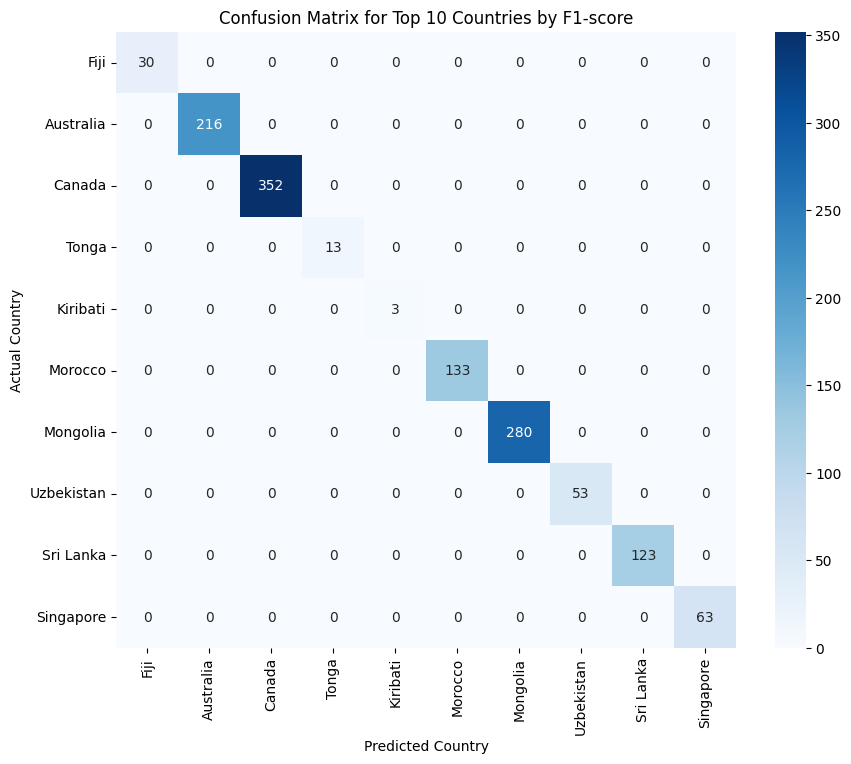

In [ ]:
# Get the names of the top 10 countries by F1-score
top_10_f1_countries = classification_report_sorted_f1.head(10).index.tolist()

# Filter the confusion matrix DataFrame to include only the top 10 F1 countries
conf_matrix_top_10_f1 = conf_matrix_df.loc[top_10_f1_countries, top_10_f1_countries]

# Visualize the confusion matrix for the top 10 F1 countries
plt.figure(figsize=(10, 8))
sns.heatmap(conf_matrix_top_10_f1, annot=True, fmt='d', cmap='Blues')

plt.title('Confusion Matrix for Top 10 Countries by F1-score')
plt.xlabel('Predicted Country')
plt.ylabel('Actual Country')
plt.show()

# Decision Tree
We gaan ook hier het land voorspellen op basis van de regio en de subregio.

In [ ]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import accuracy_score, classification_report
import pandas as pd
import numpy as np

# Select features (Region, Subregion) and target (Country)
features = ['Region', 'Subregion']
target = 'Country'

X = data_counts[features]
y = data_counts[target]

# Encode categorical features and target variable
# Use LabelEncoder for the target variable 'Country'
label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(y)

# Use one-hot encoding for features 'Region' and 'Subregion'
X_encoded = pd.get_dummies(X, columns=features)

# Split data into training and testing sets
X_train, X_test, y_train_encoded, y_test_encoded = train_test_split(
    X_encoded, y_encoded, test_size=0.3, random_state=42
)

# Initialize and train a Decision Tree classifier
decision_tree_model = DecisionTreeClassifier(random_state=42)
decision_tree_model.fit(X_train, y_train_encoded)

# Make predictions on the test set
y_pred_encoded = decision_tree_model.predict(X_test)

# Evaluate the model
accuracy = accuracy_score(y_test_encoded, y_pred_encoded)
print(f"Accuracy: {accuracy}")

# Display classification report
unique_test_labels = np.unique(y_test_encoded)
target_names_subset = label_encoder.inverse_transform(unique_test_labels)

print("\nClassification Report:")
print(classification_report(
    y_test_encoded, y_pred_encoded, labels=unique_test_labels, target_names=target_names_subset, zero_division='warn'
))

Accuracy: 0.16072555205047317

Classification Report:
                                                precision    recall  f1-score   support

                                   Afghanistan       0.00      0.00      0.00         7
                                       Albania       0.00      0.00      0.00       133
                                       Algeria       0.00      0.00      0.00       154
                                American Samoa       0.00      0.00      0.00        10
                                       Andorra       0.00      0.00      0.00        93
                                        Angola       0.00      0.00      0.00         3
                                      Anguilla       0.00      0.00      0.00        13
                           Antigua and Barbuda       0.00      0.00      0.00       185
                                     Argentina       0.00      0.00      0.00       157
                                       Armenia       0.15      1.

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


**Discuss why performance is similar between models**<br>
The performance of the Decision Tree and Naive Bayes models is very similar in this case because of the nature of the task and the features used.
<p>
Here's why they might perform so similarly:
<p>
<ol><li>Limited Features: We are using only two categorical features ('Region' and 'Subregion') to predict 'Country'. These features provide a relatively simple structure to the data in terms of how countries are grouped geographically.</li>
<li>Categorical Data: Both models handle categorical data differently, but with one-hot encoded features (which represent the presence or absence of a region/subregion), the information available to both models is essentially binary indicators.</li>
<li>Decision Tree Splits: A Decision Tree learns by making splits based on feature values. With one-hot encoded features, these splits are simply checking if a data point belongs to a specific region or subregion (e.g., "Is Region_Europe = 1?"). The initial splits in the tree will likely prioritize the most informative region/subregion features.</li>
<li>Naive Bayes Probabilities: Naive Bayes calculates probabilities based on the frequency of features within each class (country). With one-hot encoded features, this means looking at how often a country appears within a specific region or subregion.</li>
<li>Overlap in Information Captured: With only a few categorical features, the patterns and relationships that a Decision Tree can learn through splits are limited. Similarly, the probabilistic relationships that Naive Bayes can capture are also constrained by these same features. Both models are essentially trying to distinguish between countries based on their geographical location, and with only Region and Subregion, the discriminative power is limited. The way these two features partition the data is likely being interpreted in a very similar way by both algorithms, leading to similar prediction outcomes.</li>
<li>Large Number of Classes: Predicting one out of over 200 classes (countries) with only two features is a very challenging task. The inherent ambiguity in the data (multiple countries within the same subregion) limits the ceiling of accuracy for any model using only these features. Both models are likely struggling with this inherent difficulty, resulting in similar, relatively low, accuracy.</li>
</ol>
<p>
In essence, the simplicity of the feature space and the complexity of the target variable (many classes) mean that both algorithms, despite their different internal mechanisms, are extracting very similar levels of predictive power from the available information.

## Plaatje van de boom (1)

In [ ]:
from sklearn.tree import export_text

# Print the text representation of the Decision Tree up to a depth of 3
tree_text = export_text(decision_tree_model, feature_names=X_encoded.columns.tolist(), max_depth=3)
print(tree_text)

|--- Subregion_Northern America <= 0.50
|   |--- Subregion_Western Europe <= 0.50
|   |   |--- Subregion_Northern Europe <= 0.50
|   |   |   |--- Subregion_Southern Europe <= 0.50
|   |   |   |   |--- truncated branch of depth 13
|   |   |   |--- Subregion_Southern Europe >  0.50
|   |   |   |   |--- class: 92
|   |   |--- Subregion_Northern Europe >  0.50
|   |   |   |--- class: 82
|   |--- Subregion_Western Europe >  0.50
|   |   |--- class: 180
|--- Subregion_Northern America >  0.50
|   |--- class: 34



Explain the feature splits in the Decision Tree
Certainly! The text output of the Decision Tree shows the rules the tree learned to make predictions. Each line represents a node in the tree, and the lines with |--- indicate branches.

Let's break down the first few splits:

|--- Subregion_Northern America <= 0.50
This is the root node (the very top) of the tree.
Subregion_Northern America is one of the one-hot encoded features representing if the subregion is Northern America (1 if it is, 0 if it's not).
The condition <= 0.50 essentially checks if the subregion is not Northern America (since the value will be 0).
So, the tree first splits the data based on whether a data point belongs to the Northern America subregion or not.<p>
| |--- Subregion_Western Europe <= 0.50
This is the next split for data points where the subregion was not Northern America (Subregion_Northern America <= 0.50).
This condition checks if the subregion is not Western Europe.<p>
| | |--- Subregion_Northern Europe <= 0.50
This is a further split for data points that are neither Northern America nor Western Europe.
This condition checks if the subregion is not Northern Europe.<p>
| | | |--- Subregion_Southern Europe <= 0.50
Another split for data points not in Northern America, Western Europe, or Northern Europe.
This condition checks if the subregion is not Southern Europe.<p>
| | | | |--- truncated branch of depth 13
This indicates that the tree continues to split further down for this specific path based on other features, but the output is truncated at depth 3 as requested.<p>
| | | |--- Subregion_Southern Europe > 0.50
This is the other branch from the previous split, for data points where the subregion is Southern Europe.<p>
| | | | |--- class: 92
This is a leaf node (a terminal node where a prediction is made).
class: 92 means that for data points that fall into this specific combination of conditions (Not Northern America, Not Western Europe, Not Northern Europe, and IS Southern Europe), the model predicts the country encoded by the label 92. You would need to use the label_encoder.inverse_transform() method to find out which country corresponds to label 92.<p>
| | |--- Subregion_Northern Europe > 0.50
This branch is for data points not in Northern America or Western Europe, but are in Northern Europe.<p>
| | | |--- class: 82
Another leaf node, predicting the country encoded by label 82 for data points in this path.<p>
| |--- Subregion_Western Europe > 0.50
This branch is for data points not in Northern America but are in Western Europe.<p>
| | |--- class: 180
A leaf node predicting the country encoded by label 180.<p>
|--- Subregion_Northern America > 0.50
This is the other branch from the root node, for data points where the subregion is Northern America.<p>
| |--- class: 34
A leaf node predicting the country encoded by label 34 for data points in Northern America.<p>
In essence, the Decision Tree is creating a series of if-else rules based on the presence or absence of specific subregions (and potentially regions further down if the tree were deeper) to narrow down the possible country. The path taken through the tree for a given data point leads to a leaf node, and the class associated with that leaf node is the model's prediction for the country.

## Plaatje van de boom (2)

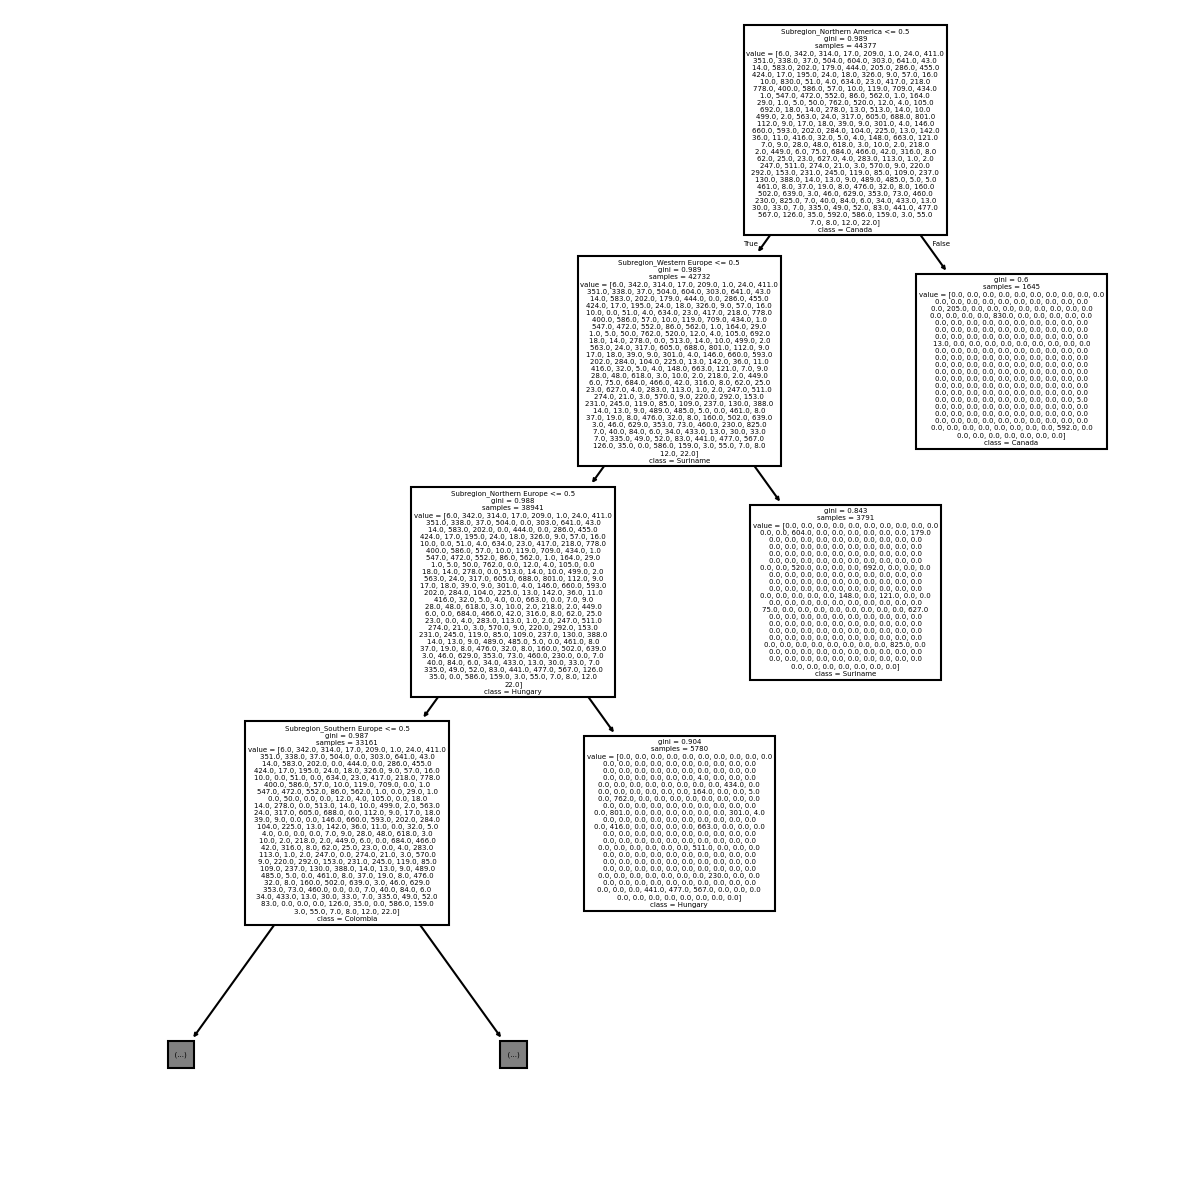

In [ ]:
from sklearn import tree

plt.figure(figsize = (10, 10), dpi = 150)
tree.plot_tree(decision_tree_model,feature_names=X_encoded.columns.tolist(), class_names=label_encoder.classes_, max_depth=3)
plt.show()

# Vergelijking tussen beide methodes

In [ ]:
from sklearn.metrics import classification_report
import pandas as pd
import numpy as np

# Ensure y_test_encoded and y_pred_encoded from the Decision Tree model are available
# (Assuming the Decision Tree cell UFuX7WyOr02f has been executed)

# Calculate the classification report for the Decision Tree as a dictionary
dt_classification_report_dict = classification_report(
    y_test_encoded, y_pred_encoded, labels=unique_test_labels, target_names=target_names_subset, output_dict=True, zero_division='warn'
)

# Convert the dictionary to a pandas DataFrame
dt_classification_report_df = pd.DataFrame(dt_classification_report_dict).T

# Remove the 'accuracy', 'macro avg', and 'weighted avg' rows
dt_classification_report_df = dt_classification_report_df.drop(['accuracy', 'macro avg', 'weighted avg'], errors='ignore')

# Assuming classification_report_df from the Naive Bayes analysis is available
# (from cell 89a0e8bd)
nb_classification_report_df = classification_report_df.copy()

# Select a few countries for comparison. Let's pick a few from the top F1 list
# and perhaps a couple that had zero scores.
countries_to_compare = ['Fiji', 'Australia', 'Canada', 'Albania', 'Afghanistan'] # Example countries

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


## Classification Report

In [ ]:
print("Classification Report Comparison:")
print("\nNaive Bayes:")
display(nb_classification_report_df.loc[countries_to_compare])

print("\nDecision Tree:")
display(dt_classification_report_df.loc[countries_to_compare])

Classification Report Comparison:

Naive Bayes:


,precision,recall,f1-score,support
Fiji,0.731707,1.0,0.845070,30.0
Australia,0.648649,1.0,0.786885,216.0
Canada,0.504298,1.0,0.670476,352.0
Albania,0.000000,0.0,0.000000,133.0
Afghanistan,0.000000,0.0,0.000000,7.0



Decision Tree:


,precision,recall,f1-score,support
Fiji,0.731707,1.0,0.845070,30.0
Australia,0.648649,1.0,0.786885,216.0
Canada,0.504298,1.0,0.670476,352.0
Albania,0.000000,0.0,0.000000,133.0
Afghanistan,0.000000,0.0,0.000000,7.0
